# Hyper-parameter search

fANOVA importance of each parameter, and every trial's success against k.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

import utils as u

FS_SMALL, FS_TINY = 9, 7  # pt: \small, \scriptsize of the paper
PAGE_WIDTH = 5.5  # in: \textwidth of the paper (\linewidth of a figure)
ROOT = Path.cwd().parent
data_path = ROOT / "results"
figs_path = ROOT / "analysis/figs"
style_path = ROOT / "analysis/figure.mplstyle"

In [2]:
data = json.loads((data_path / "data.json").read_text())
figs_path.mkdir(exist_ok=True)
plt.style.use(style_path)

In [3]:
OPTUNA_NAMES = {"k": "$k$ (neighbors)", "one_per_episode": "$\\leq$ 1 neighbor per demo", "chunk_size": "Chunk horizon $H$",
                "use_consistency": "Trajectory consistency", "w_wrist": "Wrist-camera weight",
                "temperature": "Softmax temperature $T$", "temporal_ensemble": "Temporal ensembling",
                "distance_normalization": "Distance normalization", "w_agentview": "Agent-view weight",
                "norm_preserving": "Norm preserving", "use_history": "History matching", "use_action_mode": "Mode seeking",
                "task_conditioning": "Prompt conditioning", "state_weight": "State weight", "time_weight": "Time weight",
                "use_time": "Time feature", "memory_stride": "Memory stride", "image_encoder": "Image encoder",
                "pooling_resnet18": "Feature pooling", "ensemble_coeff": "Ensembling decay",
                "use_ensemble_mode": "Ensemble mode seeking", "gripper_mode": "Gripper averaging"}  # fmt: skip

In [4]:
op = data["optuna"]
imp = list(op["importance"].items())[:8][::-1]
trials = [t for t in op["trials"] if "k" in t["params"]]
FIGSIZE = (0.48 * PAGE_WIDTH, 2.232)  # both figures side by side, each at 0.48\linewidth

## Both panels in one figure

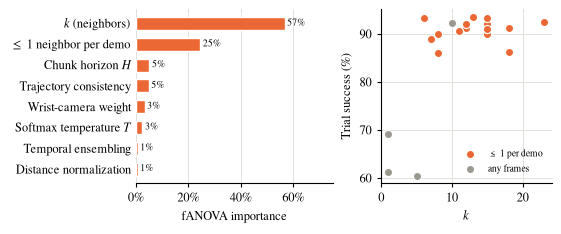

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(PAGE_WIDTH, 2.232), layout="constrained", gridspec_kw={"width_ratios": [1.15, 1]})
ax1.barh(range(len(imp)), [100 * v for _k, v in imp], color=u.Colour.KNN, height=0.62, edgecolor="white")
ax1.set_yticks(range(len(imp)), [OPTUNA_NAMES.get(k, k) for k, _v in imp])
for i, (_k, v) in enumerate(imp):
    ax1.text(100 * v + 1, i, f"{v:.0%}", va="center", fontsize=FS_TINY)
ax1.set_xlabel("fANOVA importance", fontsize=FS_SMALL)
ax1.xaxis.set_major_formatter(PercentFormatter())
ax1.set_xlim(0, 75)
ax1.tick_params(axis="y", length=0)
ax1.spines["left"].set_visible(False)
ax1.xaxis.grid(True)
ax1.set_axisbelow(True)
for one, colour, lab in ((True, u.Colour.KNN, "≤ 1 per demo"), (False, u.Colour.HUMAN, "any frames")):
    sel = [t for t in trials if bool(t["params"].get("one_per_episode", True)) == one]
    ax2.scatter([t["params"]["k"] for t in sel], [100 * t["value"] for t in sel], s=34, color=colour,
              edgecolor="white", linewidth=0.8, label=lab, zorder=3)  # fmt: skip
ax2.set_xlabel("$k$", fontsize=FS_SMALL)
ax2.set_ylabel("Trial success (%)", fontsize=FS_SMALL)
ax2.grid(True)
ax2.set_axisbelow(True)
ax2.legend(frameon=False, fontsize=FS_TINY, loc="lower right")
fig.savefig(figs_path / "optuna.pdf")

## Two separate figures

### (a) Importance of each hyper-parameter

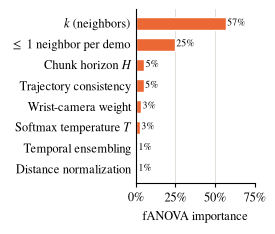

In [6]:
fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
ax.barh(range(len(imp)), [100 * v for _k, v in imp], color=u.Colour.KNN, height=0.62, edgecolor="white")
ax.set_yticks(range(len(imp)), [OPTUNA_NAMES.get(k, k) for k, _v in imp])
for i, (_k, v) in enumerate(imp):
    ax.text(100 * v + 1, i, f"{v:.0%}", va="center", fontsize=FS_TINY)
ax.set_xlabel("fANOVA importance", fontsize=FS_SMALL)
ax.xaxis.set_major_formatter(PercentFormatter())
ax.set_xlim(0, 75)
ax.tick_params(axis="y", length=0)
# ax.spines["left"].set_visible(False)
ax.xaxis.grid(True)
ax.set_axisbelow(True)
fig.savefig(figs_path / "optuna_importance.pdf")

### (b) Trial success against k

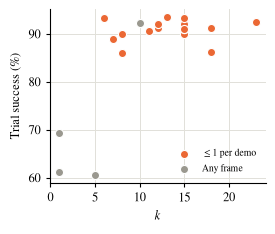

In [7]:
fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
for one, colour, lab in ((True, u.Colour.KNN, "$\\leq$1 per demo"), (False, u.Colour.HUMAN, "Any frame")):
    sel = [t for t in trials if bool(t["params"].get("one_per_episode", True)) == one]
    ax.scatter([t["params"]["k"] for t in sel], [100 * t["value"] for t in sel], s=34, color=colour,
               edgecolor="white", linewidth=0.8, label=lab, zorder=3)  # fmt: skip
ax.set_xlabel("$k$", fontsize=FS_SMALL)
ax.set_ylabel("Trial success (%)", fontsize=FS_SMALL)
ax.grid(True)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=FS_TINY, loc="lower right")
fig.savefig(figs_path / "optuna_k.pdf")